In [17]:
from langgraph.graph import StateGraph, START, END, state
from typing import TypedDict

In [26]:
class BMIState(TypedDict):
    weight_kg : float
    height_m : float
    bmi : float
    bmi_category : str

In [27]:
## Defining bmi_calculate Node function
def bmi_calculate(state:BMIState) ->BMIState:
    weight = state['weight_kg']
    height = state['height_m']
    bmi = weight / (height * height)
    state['bmi'] = round(bmi,2)

    return state


In [33]:
def bmi_categorize(state:BMIState) -> BMIState:
    bmi = state['bmi']
    if bmi < 18.5:
        category = 'Underweight'
    elif 18.5 <= bmi < 25:
        category = 'Normal weight'
    elif 25 <= bmi < 30:
        category = 'Overweight'
    else:
        category = 'Obesity'

    state['bmi_category'] = category
    return state

In [34]:
## graph creation
## Nodes Addition
graph = StateGraph(BMIState)
graph.add_node( "bmi_calculate", bmi_calculate)
graph.add_node("bmi_categorize", bmi_categorize)

## Edges Addition
graph.add_edge(START, 'bmi_calculate')
graph.add_edge('bmi_calculate', 'bmi_categorize')
graph.add_edge('bmi_categorize', END)



In [35]:
workflow= graph.compile()

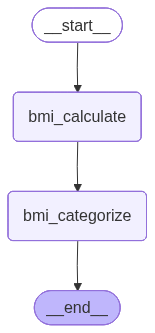

In [36]:
workflow

In [37]:
initial_values = {
    'weight_kg': 70,
    'height_m': 1.75
}
final_state = workflow.invoke(initial_values)


In [38]:
final_state

{'weight_kg': 70,
 'height_m': 1.75,
 'bmi': 22.86,
 'bmi_category': 'Normal weight'}